# 02 — EDA do sinal
Traços brutos, espectro (Welch) por grupo e por canal, correlação entre canais e curtose — agora com os **nomes dos
canais** (ordem informada pela orientadora em 03/10/2026) e **topografia**.

Canais: `Fp1 Fp2 F7 F8 F3 F4 T3 T4 C3 C4 T5 T6 P3 P4 O1 O2 Fz Cz Pz A1 A2` (ímpar = esquerda, par = direita,
z = linha média; T3/T4 = T7/T8 e T5/T6 = P7/P8 na nomenclatura nova). **A1/A2 são eletrodos de orelha** e ficam fora
das análises a partir da seção de PSD (justificativa abaixo); o restante usa os 19 canais de escalpo.
Pré-requisito: notebook 01 (cache parquet e `data/metadata.csv`).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
from scipy import signal, stats

from src.data_io import (load_metadata, load_subject, select_channels, mne_info, FS, CHANNELS, SCALP_CHANNELS,
                         REGION, ROOT)
from src.preprocess import preprocess

FIG = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
meta = load_metadata()
INFO = mne_info(SCALP_CHANNELS)

def topo(values, ax, title, cmap="RdBu_r", vlim=(None, None), label=""):
    im, _ = mne.viz.plot_topomap(np.asarray(values, float), INFO, axes=ax, show=False, cmap=cmap, vlim=vlim,
                                 names=SCALP_CHANNELS, sensors=True)
    ax.set_title(title, fontsize=10)
    plt.colorbar(im, ax=ax, shrink=0.7, label=label)

## Traços brutos (10 s) — um CTR e um TCM, todos os 21 canais

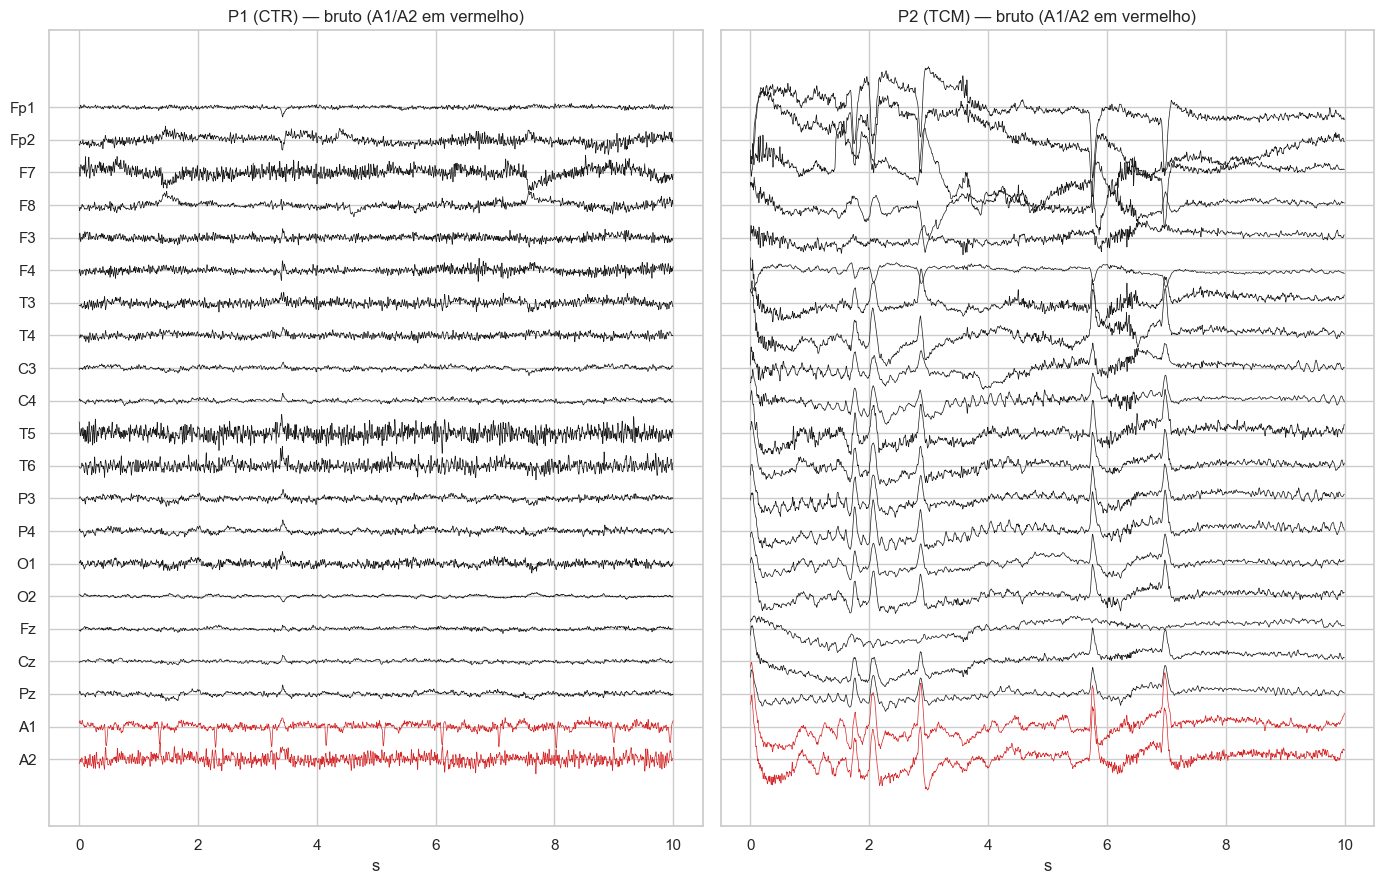

In [2]:
examples = [meta.query("group == 'CTR'").subject.iloc[0], meta.query("group == 'TCM'").subject.iloc[0]]
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharey=True)
for ax, subj in zip(axes, examples):
    seg = load_subject(subj)[30 * FS: 40 * FS]  # 30-40 s
    seg = seg - seg.mean(axis=0)
    t = np.arange(seg.shape[0]) / FS
    for i in range(seg.shape[1]):
        ax.plot(t, seg[:, i] - i * 100, lw=0.5, color="tab:red" if REGION[CHANNELS[i]] == "auricular" else "k")
    ax.set_yticks(-np.arange(len(CHANNELS)) * 100, CHANNELS)
    ax.set_title(f"{subj} ({meta.set_index('subject').loc[subj, 'group']}) — bruto (A1/A2 em vermelho)")
    ax.set_xlabel("s")
fig.tight_layout(); fig.savefig(FIG / "02_tracos_brutos.png", dpi=120)

## Por que excluir A1/A2
Canais marcados como ruins (desvio-padrão robusto > 4 MAD) por canal, com os 21 canais. A1/A2 ficam nos lóbulos
das orelhas: são locais típicos de **referência**, captam ECG e músculo da mandíbula e quase nada de córtex.

canal
A2     8
A1     7
Fp1    6
Fp2    4
T4     4
O2     4
P4     4
O1     3
Name: count, dtype: int64

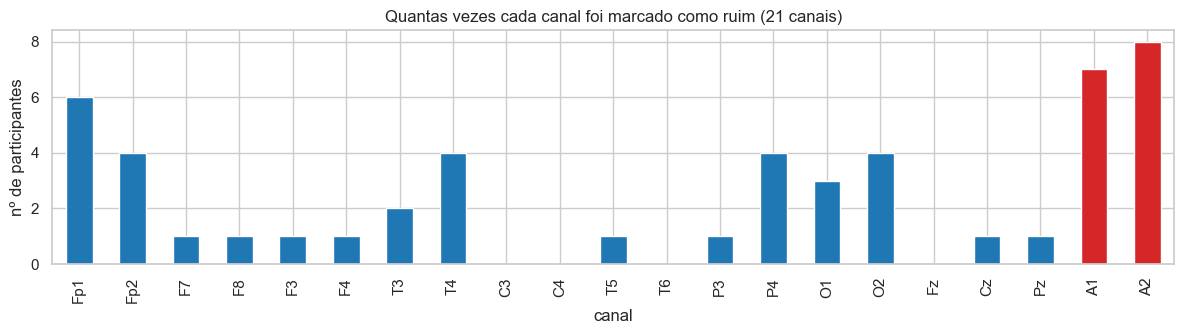

In [3]:
bad_rows = []
for r in meta.itertuples(index=False):
    _, bad = preprocess(load_subject(r.subject))
    bad_rows += [{"subject": r.subject, "canal": c} for c, b in zip(CHANNELS, bad) if b]
bad_count = pd.DataFrame(bad_rows).canal.value_counts().reindex(CHANNELS, fill_value=0)
fig, ax = plt.subplots(figsize=(12, 3.5))
bad_count.plot.bar(ax=ax, color=["tab:red" if REGION[c] == "auricular" else "tab:blue" for c in CHANNELS])
ax.set_ylabel("nº de participantes"); ax.set_title("Quantas vezes cada canal foi marcado como ruim (21 canais)")
fig.tight_layout(); fig.savefig(FIG / "02_canais_ruins.png", dpi=120)
bad_count.sort_values(ascending=False).head(8)

## PSD (Welch) bruta e pré-processada — 19 canais de escalpo
Esperado: pico de rede em 60 Hz no bruto, pico alfa (8–13 Hz) e decaimento 1/f.

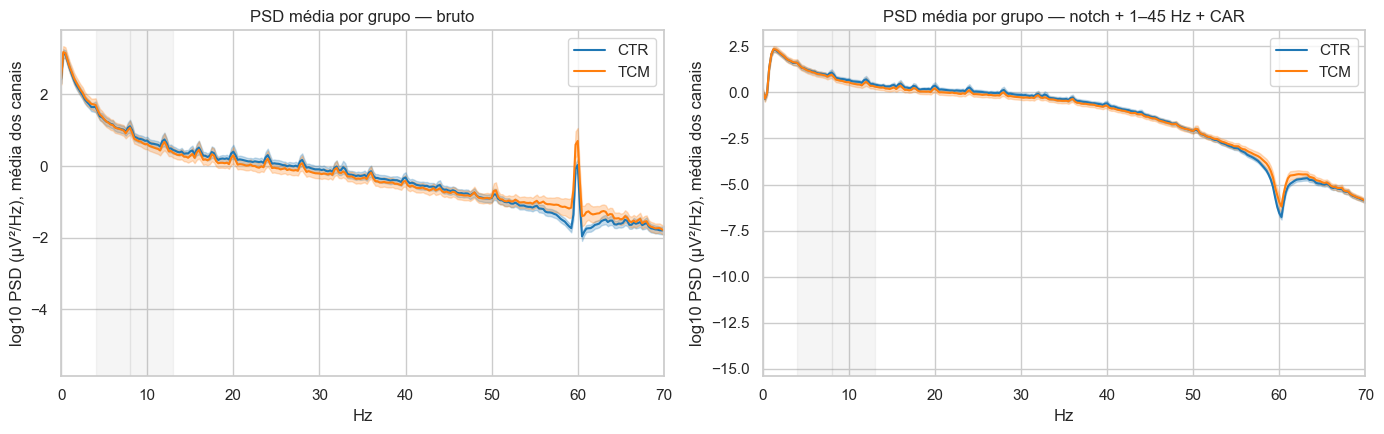

In [4]:
psd_raw, psd_clean = {}, {}
for r in meta.itertuples(index=False):
    x = select_channels(load_subject(r.subject))
    f, p = signal.welch(x, fs=FS, nperseg=4 * FS, axis=0)
    psd_raw[r.subject] = p
    y, bad = preprocess(x)
    _, psd_clean[r.subject] = signal.welch(y, fs=FS, nperseg=4 * FS, axis=0)
freqs = f

def group_mean(psds, grp, idx=slice(None)):
    subs = meta.loc[meta.group == grp, "subject"]
    return np.stack([np.log10(psds[s][:, idx].mean(axis=1)) for s in subs])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, psds, title in [(axes[0], psd_raw, "bruto"), (axes[1], psd_clean, "notch + 1–45 Hz + CAR")]:
    for grp, c in [("CTR", "tab:blue"), ("TCM", "tab:orange")]:
        g = group_mean(psds, grp)
        m, se = g.mean(0), g.std(0) / np.sqrt(len(g))
        ax.plot(freqs, m, color=c, label=grp)
        ax.fill_between(freqs, m - se, m + se, color=c, alpha=0.25)
    ax.set_xlim(0, 70); ax.set_xlabel("Hz"); ax.set_ylabel("log10 PSD (µV²/Hz), média dos canais")
    ax.set_title(f"PSD média por grupo — {title}"); ax.legend()
    for lo, hi in [(4, 8), (8, 13)]:
        ax.axvspan(lo, hi, color="grey", alpha=0.08)
fig.tight_layout(); fig.savefig(FIG / "02_psd_grupos.png", dpi=120)

### PSD por região (pré-processado)
Com os nomes dá para olhar o espectro onde ele é fisiologicamente interpretável: o alfa costuma ser mais forte em
regiões posteriores (parietal/occipital); a lentificação típica de demência aparece como mais teta/delta posterior.

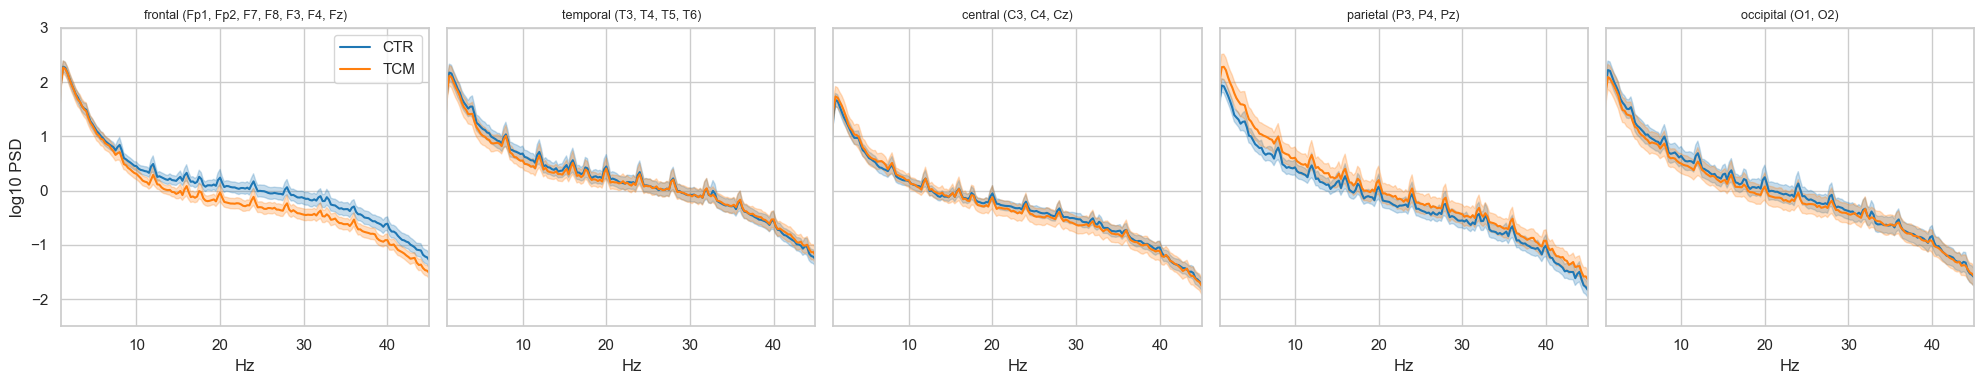

In [5]:
regions = ["frontal", "temporal", "central", "parietal", "occipital"]
fig, axes = plt.subplots(1, len(regions), figsize=(20, 4), sharey=True)
for ax, reg in zip(axes, regions):
    idx = [i for i, c in enumerate(SCALP_CHANNELS) if REGION[c] == reg]
    for grp, c in [("CTR", "tab:blue"), ("TCM", "tab:orange")]:
        g = group_mean(psd_clean, grp, idx)
        m, se = g.mean(0), g.std(0) / np.sqrt(len(g))
        ax.plot(freqs, m, color=c, label=grp); ax.fill_between(freqs, m - se, m + se, color=c, alpha=0.25)
    ax.set_xlim(1, 45); ax.set_title(f"{reg} ({', '.join(SCALP_CHANNELS[i] for i in idx)})", fontsize=9)
    ax.set_xlabel("Hz")
axes[0].set_ylabel("log10 PSD"); axes[0].legend(); axes[0].set_ylim(-2.5, 3)
fig.tight_layout(); fig.savefig(FIG / "02_psd_regioes.png", dpi=120)

## PSD por canal (pré-processado), média de todos os sujeitos — eixo em Hz

,regiao,delta_1_4,teta_4_8,alfa_8_13,beta_13_30,gama_30_45
Fp1,frontal,2.15,1.22,0.45,0.00,-0.57
Fp2,frontal,2.07,1.14,0.39,-0.03,-0.60
F7,frontal,1.51,0.70,0.28,-0.02,-0.63
F8,frontal,1.52,0.68,0.21,-0.18,-0.82
F3,frontal,1.25,0.52,0.14,-0.24,-0.89
F4,frontal,1.50,0.62,-0.01,-0.61,-1.39
T3,temporal,1.53,0.80,0.41,0.12,-0.55
T4,temporal,1.79,1.06,0.63,0.22,-0.46
C3,central,1.23,0.51,0.12,-0.30,-1.00
C4,central,1.19,0.46,0.06,-0.37,-1.05


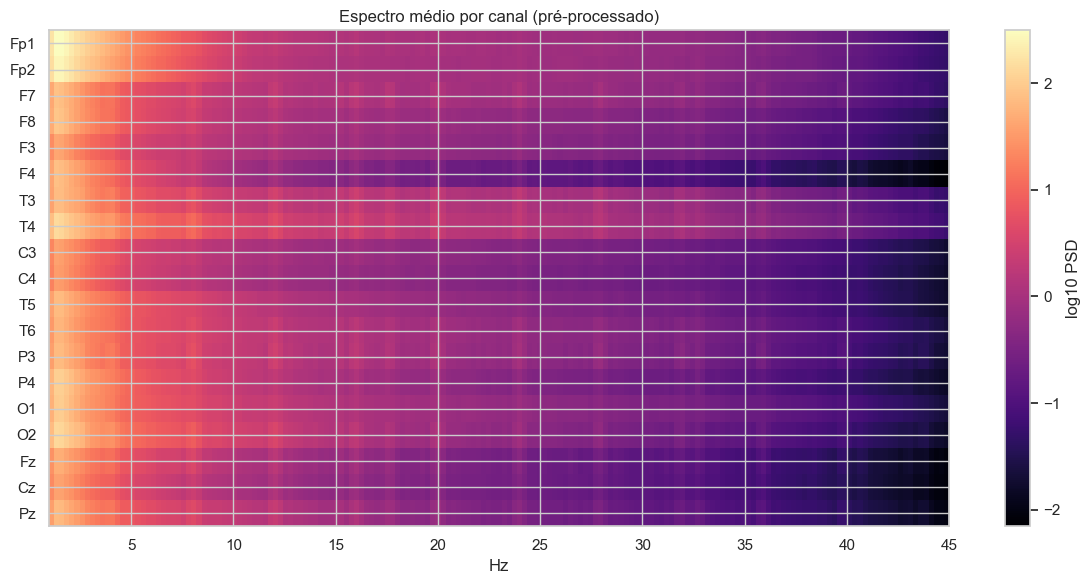

In [6]:
all_clean = np.stack([np.log10(psd_clean[s]) for s in meta.subject])  # (sujeitos, freq, canais)
mean_ch = all_clean.mean(0)
band = lambda lo, hi: mean_ch[(freqs >= lo) & (freqs < hi)].mean(0)
ch_profile = pd.DataFrame({"regiao": [REGION[c] for c in SCALP_CHANNELS], "delta_1_4": band(1, 4),
                           "teta_4_8": band(4, 8), "alfa_8_13": band(8, 13), "beta_13_30": band(13, 30),
                           "gama_30_45": band(30, 45)}, index=SCALP_CHANNELS)
display(ch_profile.round(2))

fm = (freqs >= 1) & (freqs <= 45)
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(mean_ch[fm].T, aspect="auto", cmap="magma", extent=[freqs[fm][0], freqs[fm][-1], len(SCALP_CHANNELS) - 0.5, -0.5])
ax.set_yticks(range(len(SCALP_CHANNELS)), SCALP_CHANNELS); ax.set_xlabel("Hz")
plt.colorbar(im, ax=ax, label="log10 PSD")
ax.set_title("Espectro médio por canal (pré-processado)")
fig.tight_layout(); fig.savefig(FIG / "02_psd_canais.png", dpi=120)

### Topografia da potência por banda (média dos participantes)

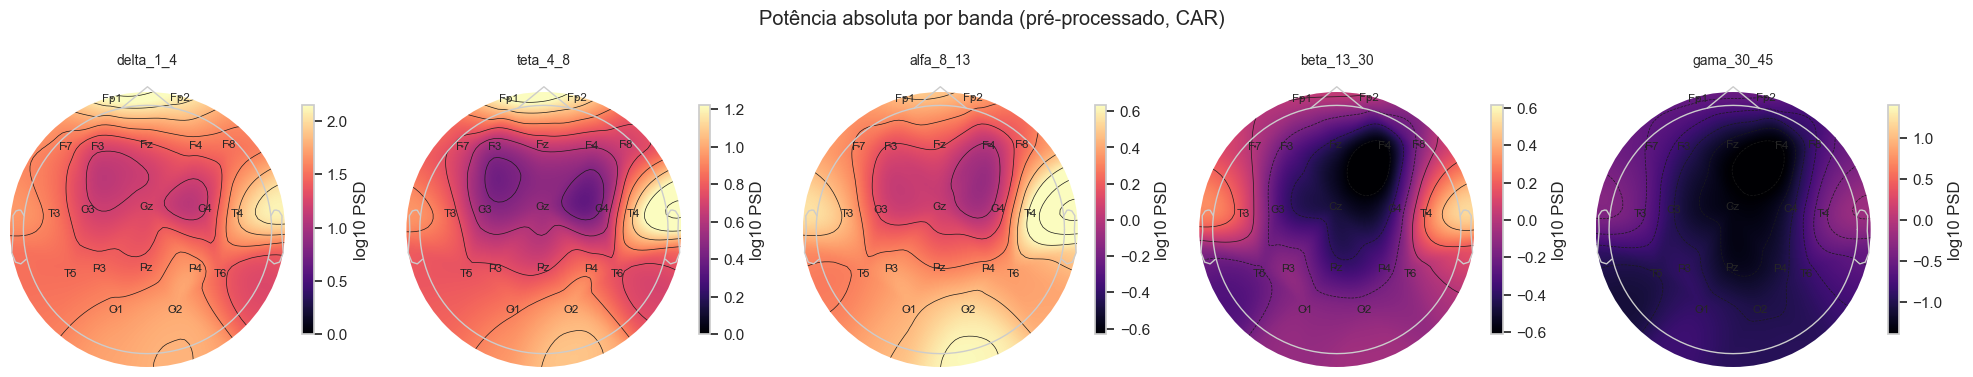

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, ["delta_1_4", "teta_4_8", "alfa_8_13", "beta_13_30", "gama_30_45"]):
    topo(ch_profile[col], ax, col, cmap="magma", label="log10 PSD")
fig.suptitle("Potência absoluta por banda (pré-processado, CAR)")
fig.tight_layout(); fig.savefig(FIG / "02_topo_bandas.png", dpi=120)

## Correlação entre canais (sem CAR, média entre sujeitos)
Validação da ordem dos canais: eletrodos próximos devem ser mais correlacionados.

Spearman(correlação, distância entre eletrodos) = -0.562


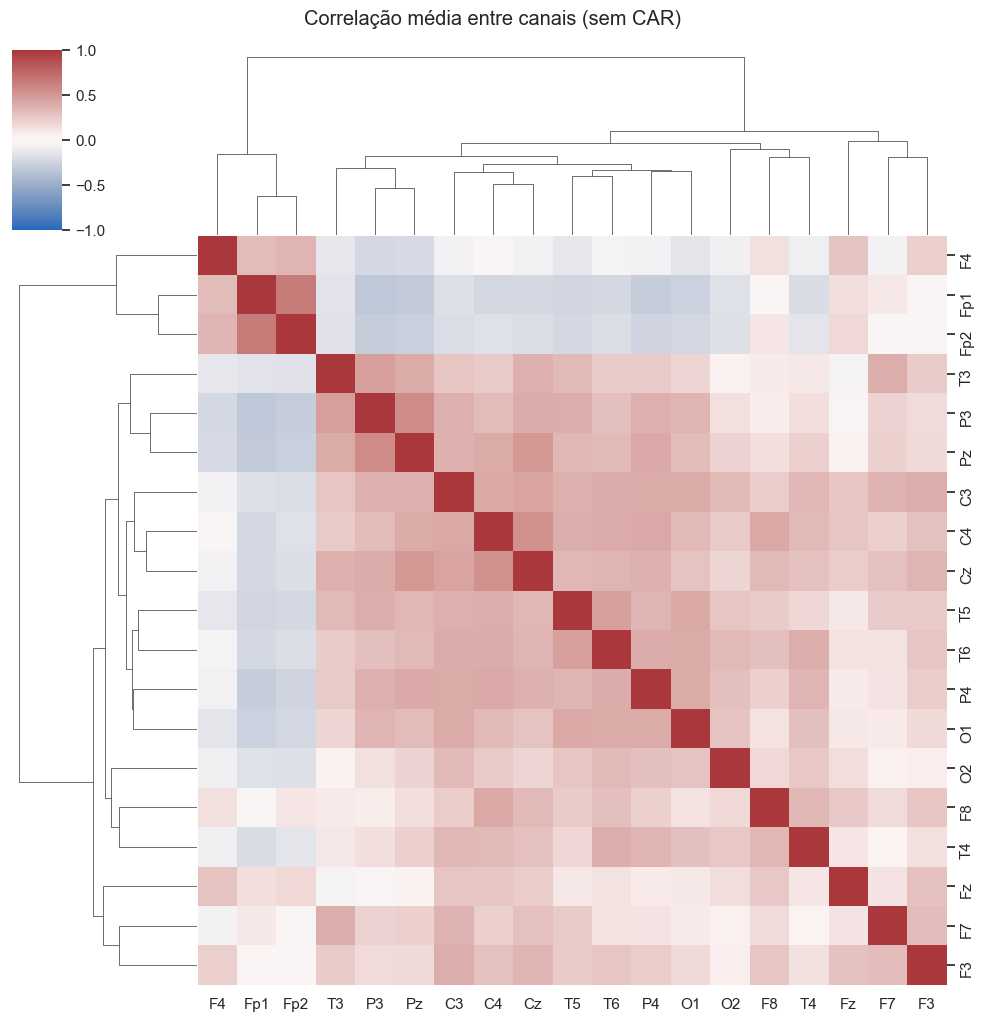

In [8]:
corrs = []
for s in meta.subject:
    y, _ = preprocess(select_channels(load_subject(s)), car=False)
    corrs.append(np.corrcoef(y.T))
C = pd.DataFrame(np.nanmean(corrs, axis=0), index=SCALP_CHANNELS, columns=SCALP_CHANNELS)
pos = INFO.get_montage().get_positions()["ch_pos"]
P = np.array([pos[c] for c in SCALP_CHANNELS]); D = np.linalg.norm(P[:, None] - P[None], axis=2)
iu = np.triu_indices(len(SCALP_CHANNELS), 1)
print("Spearman(correlação, distância entre eletrodos) = %.3f" % stats.spearmanr(C.values[iu], D[iu])[0])
g = sns.clustermap(C, cmap="vlag", vmin=-1, vmax=1, figsize=(10, 10))
g.fig.suptitle("Correlação média entre canais (sem CAR)", y=1.02)
g.savefig(FIG / "02_corr_canais.png", dpi=120)

## Curtose por canal (pré-processado)
Curtose alta = picos/artefatos transitórios (piscadas, movimento, fala — relevante no relato autobiográfico).
Piscadas devem aparecer como curtose alta em Fp1/Fp2 (perto dos olhos).

O2     13.8
F4      9.0
F3      8.3
Fp2     7.6
P4      7.4
Fp1     7.4
dtype: float32

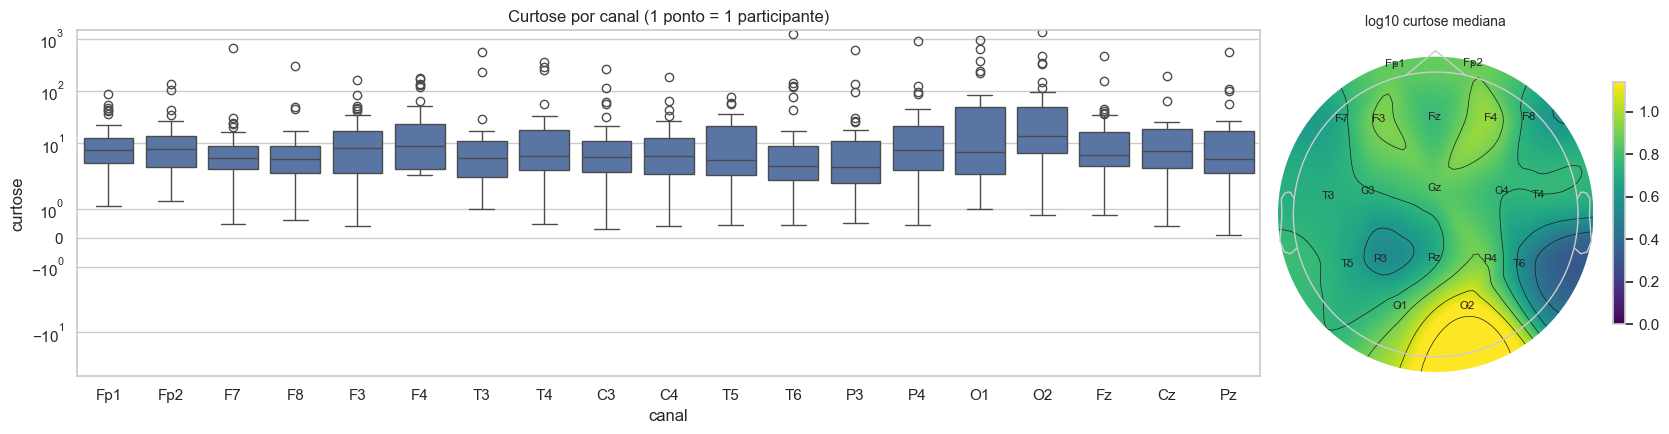

In [9]:
kurt = pd.DataFrame([stats.kurtosis(preprocess(select_channels(load_subject(s)))[0], axis=0) for s in meta.subject],
                    index=meta.subject, columns=SCALP_CHANNELS)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [3, 1]})
sns.boxplot(data=kurt.melt(var_name="canal", value_name="curtose"), x="canal", y="curtose", ax=axes[0])
axes[0].set_yscale("symlog"); axes[0].set_title("Curtose por canal (1 ponto = 1 participante)")
topo(np.log10(kurt.median()), axes[1], "log10 curtose mediana", cmap="viridis")
fig.tight_layout(); fig.savefig(FIG / "02_curtose.png", dpi=120)
kurt.median().sort_values(ascending=False).round(1).head(6)